[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch14-simple_workbook.ipynb)

# Finding the passage that holds the answer

Cut Pride and Prejudice into chunks and give each chunk a vector that
counts its words. A question becomes a vector the same way, and the chunks
nearest it by cosine are the passages a retrieval system pastes into the
prompt before the question. Which chunk does a question about the
housekeeper at Pemberley find? How often does a chunk boundary cut a fact
in two? Which words make a query that finds its own chunk?

In [1]:
#@title Setup: run this cell first
import math
import os
import re
import urllib.request
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

MIRROR_REF = "main"
TEXT_URL = f"https://raw.githubusercontent.com/josterri/predicting-the-next-words-notebooks/{MIRROR_REF}/data/pride_and_prejudice.txt"


def load_novel():
    """Pride and Prejudice as lowercase word tokens, one list per chapter."""
    if os.environ.get("PNW_TEXT"):
        text = open(os.environ["PNW_TEXT"], encoding="utf-8").read()
    else:
        try:
            text = urllib.request.urlopen(TEXT_URL).read().decode("utf-8")
        except OSError as e:
            raise RuntimeError(f"The text did not download from {TEXT_URL}: {e}. "
                               "Run this cell again; every cell below needs it.") from None
    chapters = re.split(r"(?m)^CHAPTER [IVXLC]+\.$", text)[1:]
    return [re.findall(r"[a-z]+(?:'[a-z]+)*", c.lower().replace("’", "'")) for c in chapters]


# The novel read as one list of words and cut into chunks of SIZE words; a chunk's vector counts its words. TOP chunks
# reach the prompt. A fact is the FACT words that begin at a mention of lady catherine.
SIZE, TOP, FACT = 200, 3, 20
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


def whole(name, x, lo, hi):  # a whole number typed in a cell
    if type(x) is not int or not lo <= x <= hi:
        raise Refused(f"{name} is {x!r}: {name} takes a whole number from {lo:,} to {hi:,}.")
    return x


chapters = load_novel()
words = [w for c in chapters for w in c]
chapter_of = [k + 1 for k, c in enumerate(chapters) for _ in c]  # the chapter each word stands in
chunks = [Counter(words[s:s + SIZE]) for s in range(0, len(words), SIZE)]
norms = [math.sqrt(sum(v * v for v in c.values())) for c in chunks]
where = defaultdict(dict)  # word -> {chunk: how often the word stands in it}
for j, c in enumerate(chunks):
    for w, v in c.items():
        where[w][j] = v


# Step 1: the cosine of a query with every chunk that shares a word with it; the others score 0.
def scores(query):
    q, dot = Counter(query), defaultdict(float)
    for w, v in q.items():
        for j, n in where[w].items():
            dot[j] += v * n
    qn = math.sqrt(sum(v * v for v in q.values()))
    return {j: d / (qn * norms[j]) for j, d in dot.items()}


def show_query(query):
    q = query.split() if type(query) is str else []
    if not any(w in where for w in q):
        raise Refused(f"QUERY is {query!r}: QUERY takes lowercase words, at least one of them in the novel.")
    s = scores(q)
    top = sorted(s, key=lambda j: (-s[j], j))[:TOP]
    for j in top:
        print(f"chunk {j}, chapter {chapter_of[j * SIZE]}, cosine {s[j]:.3f}: {' '.join(words[j * SIZE:j * SIZE + 10])} ...")
    fig, ax = plt.subplots(figsize=(6, 2.6), layout="constrained")
    ax.plot(range(len(chunks)), [s.get(j, 0.0) for j in range(len(chunks))], color="0.6", lw=0.8)
    ax.plot(top, [s[j] for j in top], "o", color="C3", label=f"the top {TOP}")
    ax.set(title=f"cosine of '{' '.join(q)}' with each {SIZE}-word chunk", xlabel="chunk, in reading order", ylabel="cosine")
    ax.legend()
    plt.show()


# Step 2: chunks of `size` words that start every size - overlap words. A fact is cut when no chunk holds it whole.
facts = [i for i in range(len(words) - FACT + 1) if words[i:i + 2] == ["lady", "catherine"]]


def starts(size, overlap):
    stride = size - overlap
    return [s for s in range(0, len(words), stride) if s == 0 or s - stride + size < len(words)]


def cut(size, overlap):  # per cent of the facts that no chunk holds whole
    stride = size - overlap
    held = sum(any(i + FACT <= s + size for s in range(max(i - size, 0) // stride * stride, i + 1, stride)) for i in facts)
    return 100 * (len(facts) - held) / len(facts)


def show_cuts(overlap):
    whole("OVERLAP", overlap, 0, 49)
    sizes = (50, 100, 200)
    plain, over = [cut(z, 0) for z in sizes], [cut(z, overlap) for z in sizes]
    for z, a, b in zip(sizes, plain, over):
        print(f"{z}-word chunks: {a:.1f} per cent of the facts cut in {len(starts(z, 0)):,} chunks; "
              f"with {overlap} words of overlap {b:.1f} per cent in {len(starts(z, overlap)):,} chunks")
    fig, ax = plt.subplots(figsize=(6, 2.8), layout="constrained")
    ax.bar([k - 0.2 for k in range(3)], plain, 0.4, color="C1", label="no overlap")
    ax.bar([k + 0.2 for k in range(3)], over, 0.4, color="C0", label=f"{overlap} words of overlap")
    ax.set_xticks(range(3), [f"{z}-word chunks" for z in sizes])
    ax.set(title=f"{len(facts)} facts of {FACT} words, one at each lady catherine", ylabel="cut, per cent", ylim=(0, 50))
    ax.legend()
    plt.show()


# Step 3: each chunk asks for itself, with its five rarest words or with five words from its middle, a quoted line.
spread = Counter(w for c in chunks for w in c)  # in how many chunks each word stands; ties keep the first word met


def query_of(j, kind):
    c = words[j * SIZE:(j + 1) * SIZE]
    return sorted(dict.fromkeys(c), key=lambda w: spread[w])[:5] if kind == "rarest" else c[SIZE // 2:SIZE // 2 + 5]


def rank(query, own):  # 1 + the chunks that score above the chunk the query came from
    s = scores(query)
    return 1 + sum(v > s[own] for v in s.values())


ranks = {kind: [rank(query_of(j, kind), j) for j in range(len(chunks))] for kind in ("rarest", "quoted")}


def recall(kind, k):  # per cent of the chunks found among the top k
    return 100 * sum(r <= k for r in ranks[kind]) / len(chunks)


def show_recall(k):
    ks = range(1, whole("K", k, 1, 50) + 1)
    for kind in ranks:
        print(f"{kind} words: own chunk first {recall(kind, 1):.1f} per cent, in the top {k} {recall(kind, k):.1f}")
    fig, ax = plt.subplots(figsize=(6, 2.8), layout="constrained")
    for kind, colour in zip(ranks, ("C0", "C3")):
        ax.plot(ks, [recall(kind, j) for j in ks], "o-", ms=3, color=colour, label=f"five {kind} words")
    ax.set(title=f"{len(chunks)} chunks, each searched for with five of its words", xlabel="top k",
           ylabel="own chunk found, per cent", ylim=(0, 105))
    ax.legend(loc="lower right")
    plt.show()

## 1. A query against every chunk

The cell cuts the novel into chunks of 200 words, counts the words of each,
and scores a query against every chunk by cosine. It prints the top 3
chunks with their chapters and draws the cosine along the novel. Run it for
pemberley housekeeper picture. Then set `QUERY` to `"netherfield ball"`.

chunk 54, chapter 8, cosine 0.100: as these neglect i am sure you neglect nothing that ...
chunk 379, chapter 43, cosine 0.096: saved her from something like regret she longed to inquire ...
chunk 377, chapter 43, cosine 0.072: in front a stream of some natural importance was swelled ...


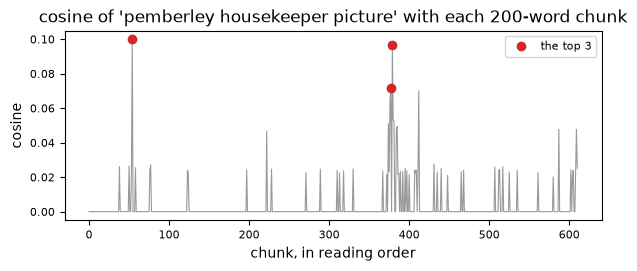

In [2]:
QUERY = "pemberley housekeeper picture"
show_query(QUERY)

### Solution

In [3]:
s = scores("pemberley housekeeper picture".split())
first, second = sorted(s, key=lambda j: (-s[j], j))[:2]
names = Counter(words[first * SIZE:(first + 1) * SIZE])["pemberley"]
display(Markdown(f"The top chunk, cosine {s[first]:.3f}, comes from chapter {chapter_of[first * SIZE]}, where pemberley "
                 f"stands {names} times and neither housekeeper nor picture does. The chunk where Elizabeth sees the "
                 f"picture with the housekeeper, chapter {chapter_of[second * SIZE]}, comes second at {s[second]:.3f}. "
                 f"Counts reward a word said often, so both chunks reach a prompt of the top {TOP}."))

The top chunk, cosine 0.100, comes from chapter 8, where pemberley stands 4 times and neither housekeeper nor picture does. The chunk where Elizabeth sees the picture with the housekeeper, chapter 43, comes second at 0.096. Counts reward a word said often, so both chunks reach a prompt of the top 3.

## 2. A fact cut by a chunk boundary

Take as a fact the 20 words that begin at each mention of lady catherine.
The cell cuts the novel into chunks of 50, 100 and 200 words and counts the
facts that no chunk holds whole; with an overlap, each chunk starts that
many words before the last one ends. Run it with no overlap. Then set
`OVERLAP` to 20.

50-word chunks: 42.0 per cent of the facts cut in 2,444 chunks; with 0 words of overlap 42.0 per cent in 2,444 chunks
100-word chunks: 17.0 per cent of the facts cut in 1,222 chunks; with 0 words of overlap 17.0 per cent in 1,222 chunks
200-word chunks: 11.0 per cent of the facts cut in 611 chunks; with 0 words of overlap 11.0 per cent in 611 chunks


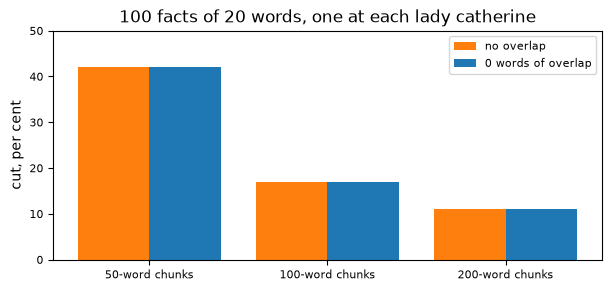

In [4]:
OVERLAP = 0
show_cuts(OVERLAP)

### Solution

In [5]:
display(Markdown(f"Without overlap, {cut(50, 0):.1f} per cent of the {len(facts)} facts are cut at 50 words, "
                 f"{cut(100, 0):.1f} at 100 and {cut(200, 0):.1f} at 200: a fact of {FACT} words is cut when it starts in "
                 f"the last {FACT - 1} words of a chunk, about {100 * (FACT - 1) / 200:.1f} per cent at 200. With 20 words of "
                 f"overlap no fact is cut, {cut(200, 20):.1f} per cent, and the index grows from {len(starts(200, 0)):,} to "
                 f"{len(starts(200, 20)):,} chunks of 200 words."))

Without overlap, 42.0 per cent of the 100 facts are cut at 50 words, 17.0 at 100 and 11.0 at 200: a fact of 20 words is cut when it starts in the last 19 words of a chunk, about 9.5 per cent at 200. With 20 words of overlap no fact is cut, 0.0 per cent, and the index grows from 611 to 679 chunks of 200 words.

## 3. Which words find their chunk

Each chunk is searched for with five of its own words: its five rarest
words, those standing in the fewest chunks, or five words from its middle,
as a reader would quote a line. The cell counts how often the chunk comes
back first, in the top 3 and in the top 10. Run it. Which query finds its
chunk, and why does the other fail?

rarest words: own chunk first 100.0 per cent, in the top 10 100.0
quoted words: own chunk first 13.1 per cent, in the top 10 43.0


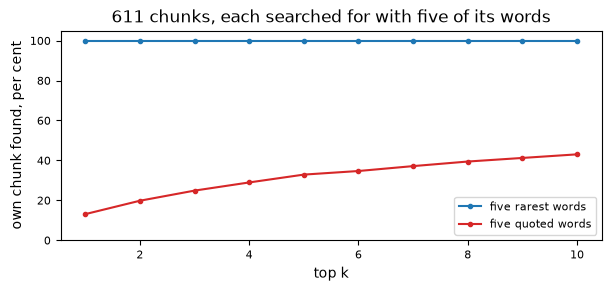

In [6]:
K = 10
show_recall(K)

### Solution

In [7]:
reach = {kind: sum(spread[w] for j in range(len(chunks)) for w in query_of(j, kind)) / (5 * len(chunks)) for kind in ranks}
display(Markdown(f"The five rarest words find their own chunk first {recall('rarest', 1):.1f} per cent of the time; such a "
                 f"word stands in {reach['rarest']:.1f} of the {len(chunks)} chunks on average, so it names them. A quoted line "
                 f"finds its chunk first {recall('quoted', 1):.1f} per cent of the time and in the top {TOP} "
                 f"{recall('quoted', TOP):.1f}: its words stand in {reach['quoted']:.0f} chunks on average and score every chunk "
                 f"that holds many of them. Recall in the top k is the retrieval stage's accuracy, one factor of a pipeline's "
                 f"end-to-end figure."))

The five rarest words find their own chunk first 100.0 per cent of the time; such a word stands in 1.5 of the 611 chunks on average, so it names them. A quoted line finds its chunk first 13.1 per cent of the time and in the top 3 24.9: its words stand in 271 chunks on average and score every chunk that holds many of them. Recall in the top k is the retrieval stage's accuracy, one factor of a pipeline's end-to-end figure.

## Appendix. The whole novel as one prompt

A long window could hold the whole novel and skip retrieval. One attention
head stores a score for every pair of positions, at 2 bytes a score. The
cell draws that memory for windows from a thousand words to the whole
novel, against the 80 GB of one large GPU.

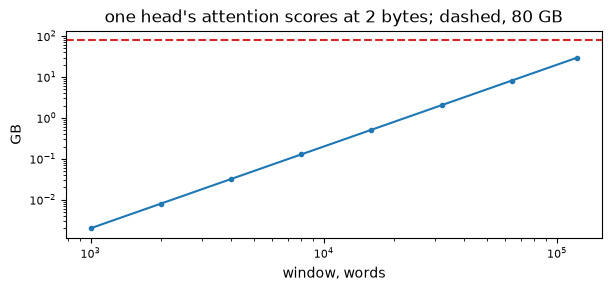

In [8]:
ns = [1_000 * 2 ** k for k in range(7)] + [len(words)]
fig, ax = plt.subplots(figsize=(6, 2.8), layout="constrained")
ax.loglog(ns, [n * n * 2 / 1e9 for n in ns], "o-", ms=3, color="C0")
ax.axhline(80, color="C3", ls="--")
ax.set(title="one head's attention scores at 2 bytes; dashed, 80 GB", xlabel="window, words", ylabel="GB")
plt.show()

**Exercise.** Set `WINDOW` to 32,768: how many GB does one head's matrix
take, and how many windows of that length does the novel fill?

In [9]:
WINDOW = 1_000
whole("WINDOW", WINDOW, 1, 10_000_000)
print(f"{WINDOW:,} words: {WINDOW ** 2 * 2 / 1e9:.2f} GB per head; the novel fills {-(-len(words) // WINDOW)} such windows")

1,000 words: 0.00 GB per head; the novel fills 123 such windows


### Solution

In [10]:
display(Markdown(f"At 32,768 words one head's matrix takes {32_768 ** 2 * 2 / 1e9:.2f} GB, and the novel's {len(words):,} "
                 f"words fill {-(-len(words) // 32_768)} such windows. As one window the novel needs "
                 f"{len(words) ** 2 * 2 / 1e9:.1f} GB per head, and every layer has many heads."))

At 32,768 words one head's matrix takes 2.15 GB, and the novel's 122,174 words fill 4 such windows. As one window the novel needs 29.9 GB per head, and every layer has many heads.